# Семинар. Линейная регрессия

Во всём ноутбуке будем использовать единый экспериментальный протокол:

- данные делятся на **train / validation / test**;
- модель обучается только на **train**;
- если у метода есть настраиваемые параметры, они выбираются по **validation**;
- **test** используется один раз — для итоговой оценки;
- перед обучением визуально проверяем структуру данных с помощью **Matrix Plot**;
- основными метриками будут $MAE$, $RMSE$ и $R^2$.

Для линейной модели

$$
\hat y = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p
$$

коэффициенты выбираются так, чтобы минимизировать выбранную функцию потерь.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from numpy.linalg import svd, cond, matrix_rank
from pandas.plotting import scatter_matrix

from sklearn.model_selection import train_test_split
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    HuberRegressor, QuantileRegressor
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.datasets import load_diabetes, load_linnerud

np.random.seed(42)


def split_3way(X, y, val_size=0.2, test_size=0.2, random_state=42, stratify=None):
    """Разбиение на train / validation / test."""
    temp_size = val_size + test_size
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=temp_size,
        random_state=random_state,
        stratify=stratify
    )

    rel_test = test_size / temp_size
    strat_temp = None
    if stratify is not None:
        _, strat_temp = train_test_split(
            stratify,
            test_size=temp_size,
            random_state=random_state,
            stratify=stratify
        )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=rel_test,
        random_state=random_state,
        stratify=strat_temp
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


def reg_metrics(y_true, y_pred, name='model'):
    return pd.Series({
        'model': name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    })


def matrix_plot(df, columns=None, title='Matrix Plot', figsize=(8, 8)):
    if columns is not None:
        df = df[columns]
    axes = scatter_matrix(df, figsize=figsize, diagonal='hist', alpha=0.55)
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def show_split_shapes(X_train, X_val, X_test):
    print('train:', np.shape(X_train), 'validation:', np.shape(X_val), 'test:', np.shape(X_test))


# 1. Линейная регрессия для линейно зависимых данных

## Теория

Начнём с наиболее благоприятного случая:

$$
y = \beta_0 + \beta_1 x + \varepsilon,
$$

где шум $\varepsilon$ имеет математическое ожидание около нуля. Если модель действительно линейна, метод наименьших квадратов должен восстановить коэффициенты близко к истинным.


train: (180, 1) validation: (60, 1) test: (60, 1)


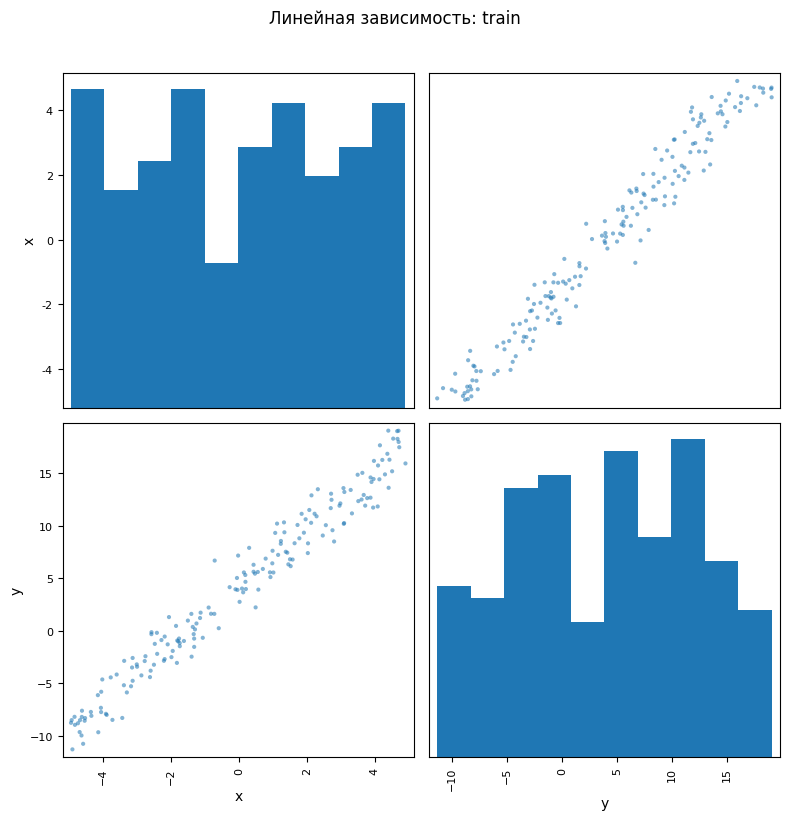

Оценённый intercept: 4.093950997199968
Оценённый коэффициент: 2.716634333872556
Истинные значения: intercept = 4.0, coefficient = 2.7
model         OLS
MAE      1.160821
RMSE     1.434942
R2       0.968331
dtype: object


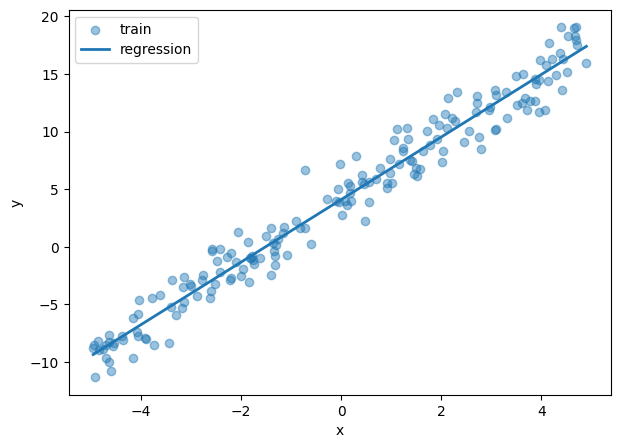

In [2]:
# Пример 1. Линейно зависимые данные
n = 300
x = np.random.uniform(-5, 5, size=n)
y = 4.0 + 2.7 * x + np.random.normal(0, 1.5, size=n)
X = x.reshape(-1, 1)

X_train, X_val, X_test, y_train, y_val, y_test = split_3way(X, y)
show_split_shapes(X_train, X_val, X_test)

train_df = pd.DataFrame({'x': X_train[:, 0], 'y': y_train})
matrix_plot(train_df, title='Линейная зависимость: train')

model = LinearRegression()
model.fit(X_train, y_train)

print('Оценённый intercept:', model.intercept_)
print('Оценённый коэффициент:', model.coef_[0])
print('Истинные значения: intercept = 4.0, coefficient = 2.7')
print(reg_metrics(y_test, model.predict(X_test), 'OLS'))

xx = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_train[:, 0], y_train, alpha=0.45, label='train')
plt.plot(xx[:, 0], model.predict(xx), linewidth=2, label='regression')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


Validation здесь не используется: у обычной линейной регрессии нет гиперпараметра, который необходимо подбирать. Test остаётся независимой выборкой для финальной оценки.


# 2. Подбор коэффициента регрессии перебором по сетке

## Теория

Для одного коэффициента можно явно проверить набор значений

$$
\beta \in \{\beta^{(1)},\ldots,\beta^{(m)}\}
$$

и для каждого вычислить ошибку на $n$ объектах. Тогда сложность составляет примерно

$$
O(nm).
$$

Если одновременно перебирать $p$ коэффициентов и для каждого использовать $m$ значений, число комбинаций станет $m^p$, то есть сложность вырастет до

$$
O(nm^p).
$$

Это и объясняет, почему полный grid search быстро становится непрактичным при росте числа признаков.


Лучший beta по сетке: 2.72
Соответствующий intercept: 4.093985591025864
model    Grid search
MAE         1.160313
RMSE        1.434128
R2          0.968367
dtype: object


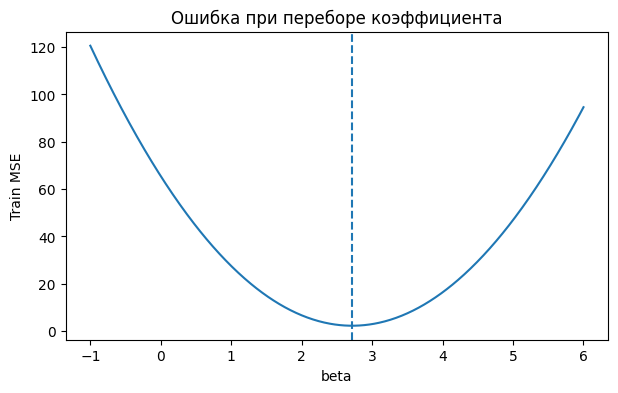

В этом примере проверено 701 коэффициентов на 180 объектах: ~126,180 элементарных проверок ошибки.
Для p=10 и m=701 полный перебор потребовал бы порядка 701^10 комбинаций.


In [3]:
# Пример 2. Перебор одного коэффициента на центрированных данных
# Центрирование позволяет убрать свободный член из перебора.
xtr = X_train[:, 0]
xte = X_test[:, 0]

x_mean = xtr.mean()
y_mean = y_train.mean()

xtr_c = xtr - x_mean
ytr_c = y_train - y_mean

beta_grid = np.linspace(-1, 6, 701)
train_mse = []

for beta in beta_grid:
    pred = beta * xtr_c
    train_mse.append(np.mean((ytr_c - pred) ** 2))

train_mse = np.array(train_mse)
best_beta = beta_grid[np.argmin(train_mse)]
best_intercept = y_mean - best_beta * x_mean

y_pred_grid = best_intercept + best_beta * xte

print('Лучший beta по сетке:', best_beta)
print('Соответствующий intercept:', best_intercept)
print(reg_metrics(y_test, y_pred_grid, 'Grid search'))

plt.figure(figsize=(7, 4))
plt.plot(beta_grid, train_mse)
plt.axvline(best_beta, linestyle='--')
plt.xlabel('beta')
plt.ylabel('Train MSE')
plt.title('Ошибка при переборе коэффициента')
plt.show()

m = len(beta_grid)
n_train = len(y_train)
print(f'В этом примере проверено {m} коэффициентов на {n_train} объектах: ~{m*n_train:,} элементарных проверок ошибки.')
print('Для p=10 и m=701 полный перебор потребовал бы порядка 701^10 комбинаций.')


# 3. Расчёт коэффициентов линейной регрессии с помощью SVD

## Теория

Запишем модель в матричной форме:

$$
\mathbf y = \mathbf X \boldsymbol\beta + \boldsymbol\varepsilon.
$$

Если

$$
\mathbf X = U\Sigma V^T,
$$

то псевдообратная матрица равна

$$
\mathbf X^+ = V\Sigma^+U^T,
$$

а решение наименьших квадратов можно записать как

$$
\hat{\boldsymbol\beta} = \mathbf X^+\mathbf y.
$$

SVD особенно полезно, когда матрица близка к вырожденной или имеет неполный ранг.


In [4]:
# Пример 3. Решение линейной регрессии через SVD
Xtr_design = np.column_stack([np.ones(len(X_train)), X_train[:, 0]])
Xte_design = np.column_stack([np.ones(len(X_test)), X_test[:, 0]])

U, s, VT = svd(Xtr_design, full_matrices=False)
S_inv = np.diag(1.0 / s)
beta_svd = VT.T @ S_inv @ U.T @ y_train

y_pred_svd = Xte_design @ beta_svd

print('Коэффициенты SVD [intercept, beta]:', beta_svd)
print('Коэффициенты sklearn:', [model.intercept_, model.coef_[0]])
print(reg_metrics(y_test, y_pred_svd, 'SVD'))


Коэффициенты SVD [intercept, beta]: [4.093951   2.71663433]
Коэффициенты sklearn: [np.float64(4.093950997199968), np.float64(2.716634333872556)]
model         SVD
MAE      1.160821
RMSE     1.434942
R2       0.968331
dtype: object


# 4. Линейная регрессия для нелинейной и экспоненциальной зависимости

## Теория

Линейная регрессия является линейной **по параметрам**, но признаки могут быть нелинейными функциями исходной переменной.

Например,

$$
\hat y = \beta_0 + \beta_1x + \beta_2x^2
$$

остаётся линейной регрессией относительно коэффициентов $\beta$.

Сначала покажем, что происходит при прямой попытке обучить модель на исходном $x$, затем добавим полиномиальные и экспоненциальные признаки.


train: (216, 1) validation: (72, 1) test: (72, 1)


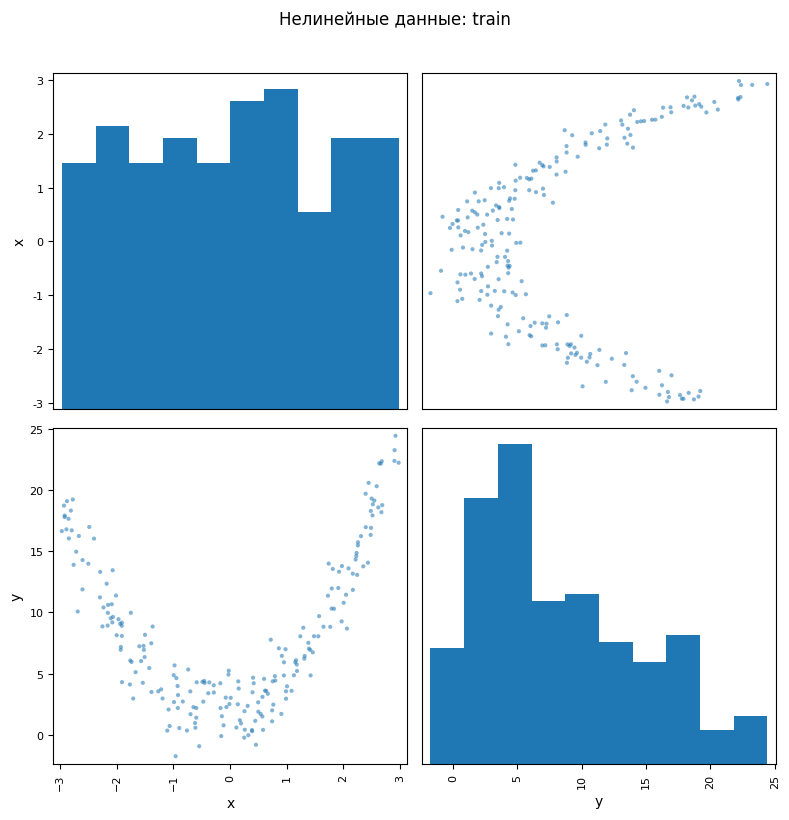

   degree  val_RMSE
0       1  5.723062
1       2  1.812750
2       3  1.815272
3       4  1.810282
4       5  1.811533
Лучший degree по validation: 2
                 model       MAE      RMSE        R2
0                raw x  5.173455  6.269687  0.044958
1  polynomial degree=2  1.469369  1.864299  0.915557


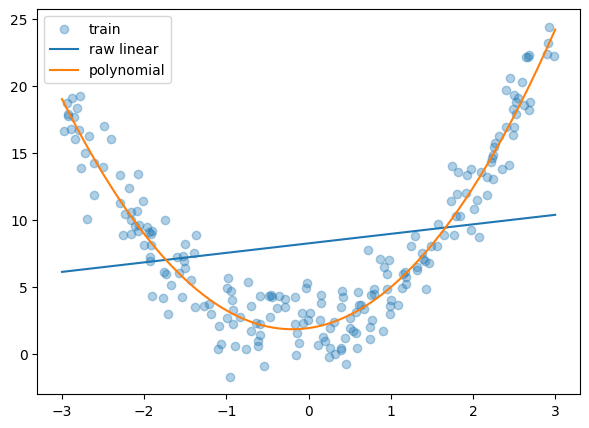

In [5]:
# Пример 4A. Квадратичная зависимость: raw x против полиномиальных признаков
n = 360
x_nl = np.random.uniform(-3, 3, n)
y_nl = 1.5 + 0.8 * x_nl + 2.2 * x_nl**2 + np.random.normal(0, 1.8, n)
X_nl = x_nl.reshape(-1, 1)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_nl, y_nl)
show_split_shapes(Xtr, Xv, Xte)
matrix_plot(pd.DataFrame({'x': Xtr[:, 0], 'y': ytr}), title='Нелинейные данные: train')

raw = LinearRegression().fit(Xtr, ytr)

rows = []
models_poly = {}
for degree in range(1, 6):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('lin', LinearRegression())
    ])
    pipe.fit(Xtr, ytr)
    val_rmse = np.sqrt(mean_squared_error(yv, pipe.predict(Xv)))
    rows.append({'degree': degree, 'val_RMSE': val_rmse})
    models_poly[degree] = pipe

poly_results = pd.DataFrame(rows)
min_poly_rmse = poly_results.val_RMSE.min()
# При почти одинаковом качестве выбираем более простую модель.
best_degree = int(poly_results.loc[poly_results.val_RMSE <= 1.01*min_poly_rmse, 'degree'].min())
best_poly = models_poly[best_degree]

print(poly_results)
print('Лучший degree по validation:', best_degree)
print(pd.DataFrame([
    reg_metrics(yte, raw.predict(Xte), 'raw x'),
    reg_metrics(yte, best_poly.predict(Xte), f'polynomial degree={best_degree}')
]))

xx = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(Xtr[:, 0], ytr, alpha=0.35, label='train')
plt.plot(xx[:, 0], raw.predict(xx), label='raw linear')
plt.plot(xx[:, 0], best_poly.predict(xx), label='polynomial')
plt.legend()
plt.show()


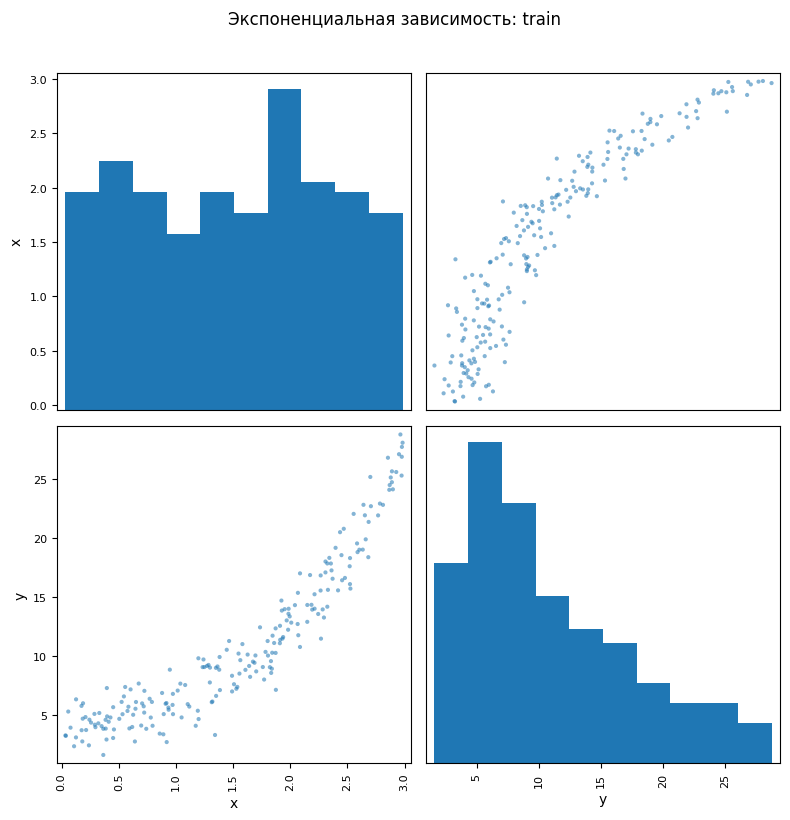

Лучший gamma по validation: 1.2
            model       MAE      RMSE        R2
0           raw x  2.164378  2.542598  0.838651
1  x + exp(1.20x)  1.107297  1.413437  0.950139


In [6]:
# Пример 4B. Экспоненциальная зависимость: raw x против exp(gamma*x)
n = 360
x_exp = np.random.uniform(0, 3, n)
y_exp = 2.0 + 1.7 * np.exp(0.9 * x_exp) + np.random.normal(0, 1.5, n)
X_exp = x_exp.reshape(-1, 1)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_exp, y_exp)
matrix_plot(pd.DataFrame({'x': Xtr[:, 0], 'y': ytr}), title='Экспоненциальная зависимость: train')

raw_exp = LinearRegression().fit(Xtr, ytr)

gamma_grid = np.linspace(0.3, 1.5, 25)
exp_models = {}
exp_rows = []

for gamma in gamma_grid:
    Xtr_e = np.column_stack([Xtr[:, 0], np.exp(gamma * Xtr[:, 0])])
    Xv_e = np.column_stack([Xv[:, 0], np.exp(gamma * Xv[:, 0])])
    m = LinearRegression().fit(Xtr_e, ytr)
    rmse = np.sqrt(mean_squared_error(yv, m.predict(Xv_e)))
    exp_rows.append({'gamma': gamma, 'val_RMSE': rmse})
    exp_models[float(gamma)] = m

exp_table = pd.DataFrame(exp_rows)
best_gamma = float(exp_table.loc[exp_table.val_RMSE.idxmin(), 'gamma'])
best_exp = exp_models[best_gamma]
Xte_e = np.column_stack([Xte[:, 0], np.exp(best_gamma * Xte[:, 0])])

print('Лучший gamma по validation:', best_gamma)
print(pd.DataFrame([
    reg_metrics(yte, raw_exp.predict(Xte), 'raw x'),
    reg_metrics(yte, best_exp.predict(Xte_e), f'x + exp({best_gamma:.2f}x)')
]))


# 5. Линейная регрессия для нормально распределённых признаков

## Теория

Нормальность самих признаков не является обязательным условием OLS. Однако нормальное распределение удобно для демонстрации классической линейной модели и анализа облака наблюдений.


train: (300, 4) validation: (100, 4) test: (100, 4)


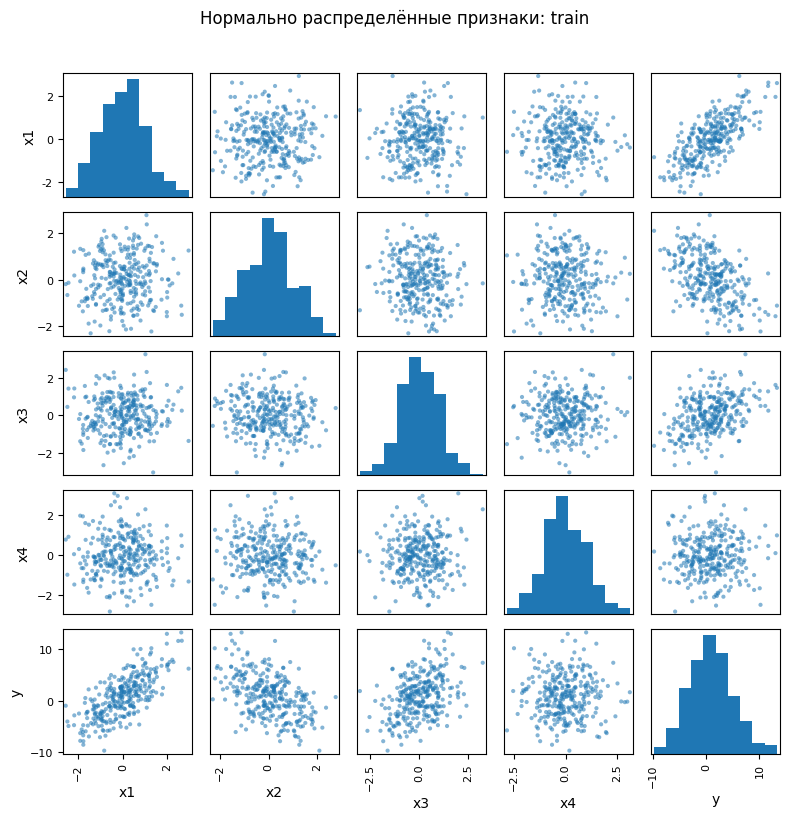

Истинные beta: [ 3.  -2.   1.5  0. ]
Оценённые beta: [ 2.98888758 -2.01778408  1.50263461 -0.11354013]
model    OLS normal X
MAE          0.979932
RMSE          1.18948
R2           0.922124
dtype: object


In [7]:
# Пример 5. Несколько нормально распределённых признаков
n, p = 500, 4
X_norm = np.random.normal(size=(n, p))
beta_true = np.array([3.0, -2.0, 1.5, 0.0])
y_norm = 1.0 + X_norm @ beta_true + np.random.normal(0, 1.2, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_norm, y_norm)
show_split_shapes(Xtr, Xv, Xte)

cols = [f'x{i+1}' for i in range(p)]
df = pd.DataFrame(Xtr, columns=cols)
df['y'] = ytr
matrix_plot(df, title='Нормально распределённые признаки: train')

norm_model = LinearRegression().fit(Xtr, ytr)
print('Истинные beta:', beta_true)
print('Оценённые beta:', norm_model.coef_)
print(reg_metrics(yte, norm_model.predict(Xte), 'OLS normal X'))


# 6. Линейная регрессия для данных с аутлаерами

## Теория

Квадратичная ошибка сильно штрафует большие остатки:

$$
L_{MSE} = \frac{1}{n}\sum_{i=1}^n (y_i-\hat y_i)^2.
$$

Поэтому несколько экстремальных наблюдений могут заметно сдвинуть прямую регрессии.


train: (216, 1) validation: (72, 1) test: (72, 1)


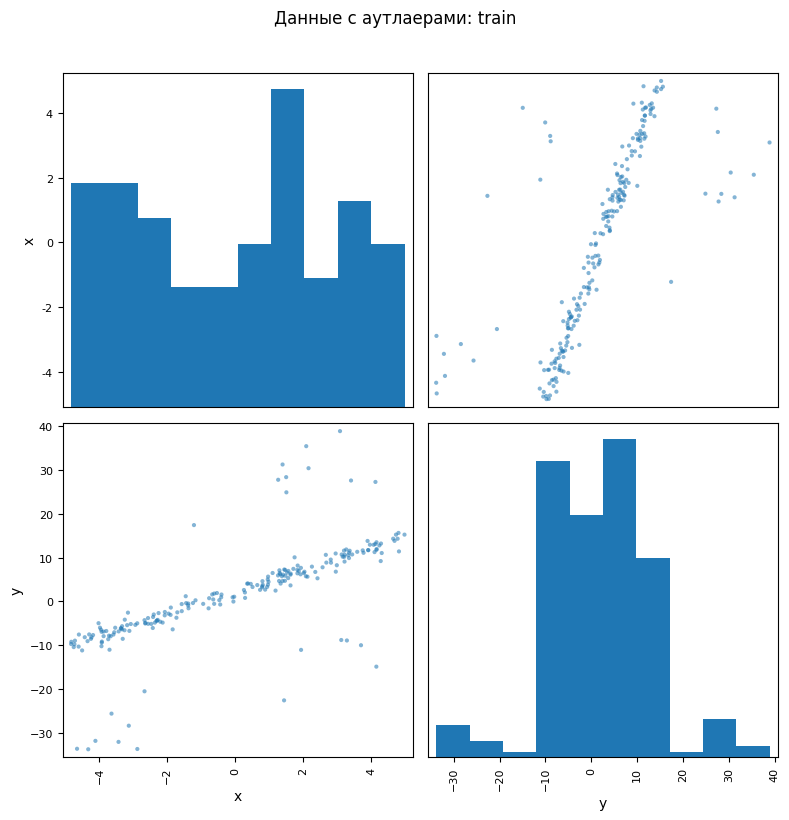

Коэффициенты OLS: 1.5903992931915625 2.903406697821467
model    OLS with outliers
MAE               3.137473
RMSE              6.684522
R2                0.547652
dtype: object


In [8]:
# Пример 6. Добавляем аутлаеры в линейные данные
n = 360
x_out = np.random.uniform(-5, 5, n)
y_clean = 2.0 + 2.5 * x_out + np.random.normal(0, 1.2, n)
y_out = y_clean.copy()

outlier_idx = np.random.choice(n, size=36, replace=False)
is_outlier = np.zeros(n, dtype=bool)
is_outlier[outlier_idx] = True
y_out[outlier_idx] += np.random.choice([-1, 1], size=len(outlier_idx)) * np.random.uniform(15, 30, len(outlier_idx))

X_out = x_out.reshape(-1, 1)
Xtr_o, Xv_o, Xte_o, ytr_o, yv_o, yte_o = split_3way(X_out, y_out)
_, _, _, otr_o, ov_o, ote_o = split_3way(X_out, is_outlier)
show_split_shapes(Xtr_o, Xv_o, Xte_o)
matrix_plot(pd.DataFrame({'x': Xtr_o[:, 0], 'y': ytr_o}), title='Данные с аутлаерами: train')

ols_out = LinearRegression().fit(Xtr_o, ytr_o)
print('Коэффициенты OLS:', ols_out.intercept_, ols_out.coef_[0])
print(reg_metrics(yte_o, ols_out.predict(Xte_o), 'OLS with outliers'))


# 7. Линейная регрессия после очищения аутлаеров

Аутлаеры будем обнаруживать **только на train**, чтобы не использовать информацию test-выборки при обучении. Сначала строим предварительную OLS-модель, затем оцениваем остатки и удаляем наблюдения с большим robust z-score на основе медианы и MAD.


Удалено train-наблюдений: 24 из 216
До очистки: 1.5903992931915625 2.903406697821467
После очистки: 2.0284473229232174 2.512361322628492
Метрики на полном test (включая test-аутлаеры):
             model       MAE      RMSE        R2
0  before cleaning  3.137473  6.684522  0.547652
1   after cleaning  2.770658  6.645014  0.552983

Метрики только на обычных test-наблюдениях:
             model       MAE      RMSE        R2
0  before cleaning  1.309229  1.618917  0.950741
1   after cleaning  0.857243  1.088073  0.977749


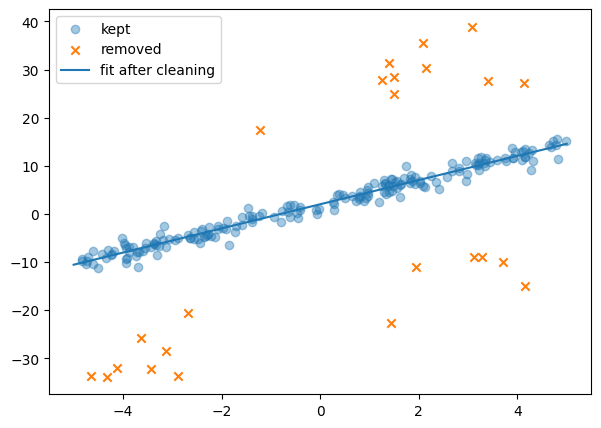

In [9]:
# Пример 7. Очистка train по остаткам через MAD
initial = LinearRegression().fit(Xtr_o, ytr_o)
resid = ytr_o - initial.predict(Xtr_o)

med = np.median(resid)
mad = np.median(np.abs(resid - med))
robust_z = 0.6745 * (resid - med) / (mad + 1e-12)
keep = np.abs(robust_z) <= 3.5

Xtr_clean = Xtr_o[keep]
ytr_clean = ytr_o[keep]

clean_model = LinearRegression().fit(Xtr_clean, ytr_clean)

print('Удалено train-наблюдений:', (~keep).sum(), 'из', len(keep))
print('До очистки:', ols_out.intercept_, ols_out.coef_[0])
print('После очистки:', clean_model.intercept_, clean_model.coef_[0])
print('Метрики на полном test (включая test-аутлаеры):')
print(pd.DataFrame([
    reg_metrics(yte_o, ols_out.predict(Xte_o), 'before cleaning'),
    reg_metrics(yte_o, clean_model.predict(Xte_o), 'after cleaning')
]))

clean_test = ~ote_o
print()
print('Метрики только на обычных test-наблюдениях:')
print(pd.DataFrame([
    reg_metrics(yte_o[clean_test], ols_out.predict(Xte_o[clean_test]), 'before cleaning'),
    reg_metrics(yte_o[clean_test], clean_model.predict(Xte_o[clean_test]), 'after cleaning')
]))

plt.figure(figsize=(7, 5))
plt.scatter(Xtr_o[keep, 0], ytr_o[keep], alpha=0.4, label='kept')
plt.scatter(Xtr_o[~keep, 0], ytr_o[~keep], marker='x', label='removed')
xx = np.linspace(-5, 5, 200).reshape(-1, 1)
plt.plot(xx[:, 0], clean_model.predict(xx), label='fit after cleaning')
plt.legend()
plt.show()


# 8. Аутлаеры и разные функции потерь

Сравним три подхода:

- OLS — квадратичная потеря;
- Huber — квадратичная ошибка для небольших остатков и линейная для больших;
- Quantile regression при $q=0.5$ — аналог медианной регрессии, основанный на pinball loss и значительно менее чувствительный к крупным выбросам.

Параметр $\epsilon$ для Huber выберем по validation.


In [10]:
# Пример 8. Сравнение функций потерь
huber_eps = [1.1, 1.2, 1.35, 1.5, 1.75, 2.0]
huber_rows = []
huber_models = {}

for eps in huber_eps:
    m = HuberRegressor(epsilon=eps, max_iter=2000).fit(Xtr_o, ytr_o)
    rmse = np.sqrt(mean_squared_error(yv_o, m.predict(Xv_o)))
    huber_rows.append({'epsilon': eps, 'val_RMSE': rmse})
    huber_models[eps] = m

huber_table = pd.DataFrame(huber_rows)
best_eps = float(huber_table.loc[huber_table.val_RMSE.idxmin(), 'epsilon'])
best_huber = huber_models[best_eps]

quant = QuantileRegressor(quantile=0.5, alpha=0.0, solver='highs').fit(Xtr_o, ytr_o)

comparison = pd.DataFrame([
    reg_metrics(yte_o, ols_out.predict(Xte_o), 'squared loss / OLS'),
    reg_metrics(yte_o, best_huber.predict(Xte_o), f'Huber eps={best_eps}'),
    reg_metrics(yte_o, quant.predict(Xte_o), 'quantile q=0.5')
])

print(huber_table)
print('Полный test:')
print(comparison)

print()
print('Test без размеченных аутлаеров:')
print(pd.DataFrame([
    reg_metrics(yte_o[clean_test], ols_out.predict(Xte_o[clean_test]), 'squared loss / OLS'),
    reg_metrics(yte_o[clean_test], best_huber.predict(Xte_o[clean_test]), f'Huber eps={best_eps}'),
    reg_metrics(yte_o[clean_test], quant.predict(Xte_o[clean_test]), 'quantile q=0.5')
]))


   epsilon  val_RMSE
0     1.10  6.097044
1     1.20  6.096402
2     1.35  6.095864
3     1.50  6.094950
4     1.75  6.093692
5     2.00  6.093233
Полный test:
                model       MAE      RMSE        R2
0  squared loss / OLS  3.137473  6.684522  0.547652
1       Huber eps=2.0  2.774287  6.637360  0.554013
2      quantile q=0.5  2.774923  6.648551  0.552507

Test без размеченных аутлаеров:
                model       MAE      RMSE        R2
0  squared loss / OLS  1.309229  1.618917  0.950741
1       Huber eps=2.0  0.867834  1.104941  0.977054
2      quantile q=0.5  0.863980  1.101197  0.977209


# 9. Линейная регрессия для смеси двух нормальных распределений

## Идея

Если данные являются смесью двух существенно различных режимов, одна прямая пытается усреднить две зависимости. Если принадлежность к режиму известна или может быть корректно восстановлена отдельным алгоритмом, две локальные модели могут работать лучше одной глобальной.


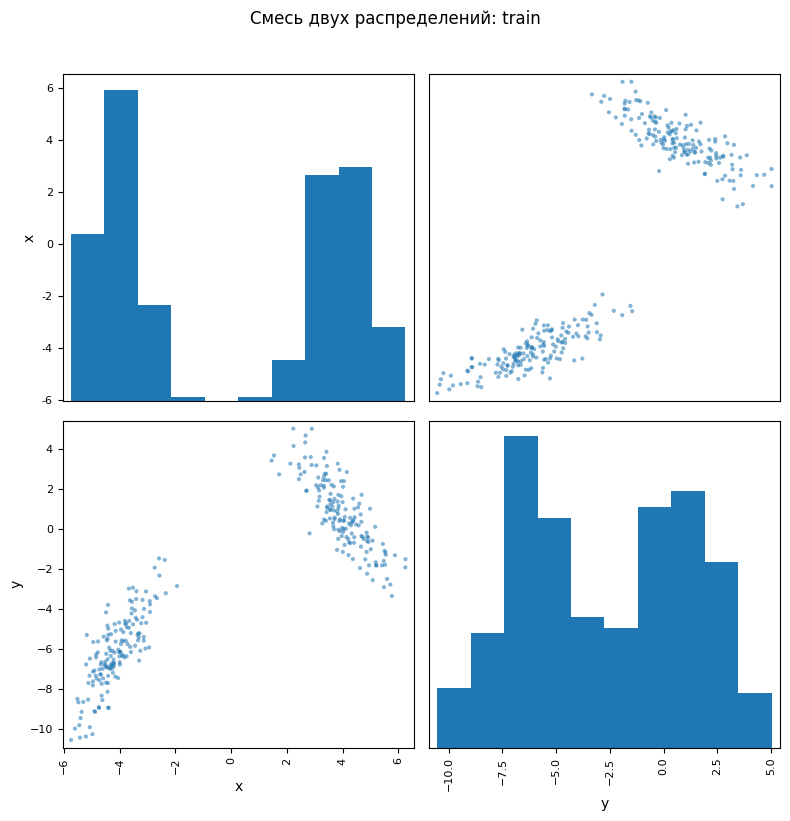

              model       MAE      RMSE        R2
0  one global model  1.567488  1.996198  0.696034
1        two models  0.779665  0.961337  0.929503


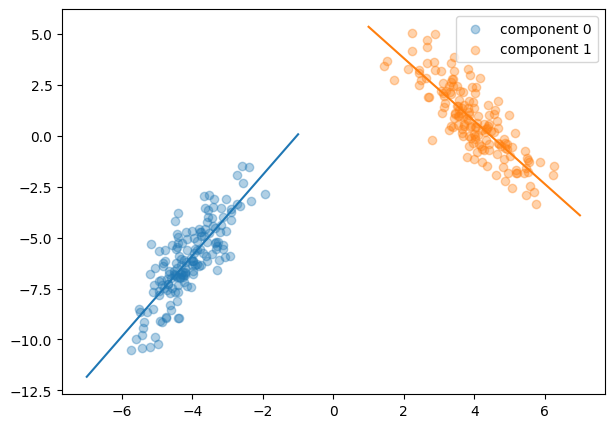

In [11]:
# Пример 9. Два удалённых кластера с разными линейными законами
n0 = n1 = 260
x0 = np.random.normal(-4.0, 0.8, n0)
x1 = np.random.normal(4.0, 0.9, n1)
y0 = 2.2 * x0 + 3.0 + np.random.normal(0, 1.0, n0)
y1 = -1.6 * x1 + 7.0 + np.random.normal(0, 1.0, n1)

X_mix = np.concatenate([x0, x1]).reshape(-1, 1)
y_mix = np.concatenate([y0, y1])
g_mix = np.array([0]*n0 + [1]*n1)

# Сначала делим индексы со стратификацией по компоненте смеси.
idx = np.arange(len(y_mix))
idx_train, idx_temp = train_test_split(idx, test_size=0.4, random_state=42, stratify=g_mix)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=42, stratify=g_mix[idx_temp])

Xtr, Xv, Xte = X_mix[idx_train], X_mix[idx_val], X_mix[idx_test]
ytr, yv, yte = y_mix[idx_train], y_mix[idx_val], y_mix[idx_test]
gtr, gv, gte = g_mix[idx_train], g_mix[idx_val], g_mix[idx_test]

matrix_plot(pd.DataFrame({'x': Xtr[:, 0], 'y': ytr}), title='Смесь двух распределений: train')

single = LinearRegression().fit(Xtr, ytr)
sep0 = LinearRegression().fit(Xtr[gtr == 0], ytr[gtr == 0])
sep1 = LinearRegression().fit(Xtr[gtr == 1], ytr[gtr == 1])

pred_sep = np.empty_like(yte)
pred_sep[gte == 0] = sep0.predict(Xte[gte == 0])
pred_sep[gte == 1] = sep1.predict(Xte[gte == 1])

print(pd.DataFrame([
    reg_metrics(yte, single.predict(Xte), 'one global model'),
    reg_metrics(yte, pred_sep, 'two models')
]))

plt.figure(figsize=(7, 5))
plt.scatter(Xtr[gtr==0, 0], ytr[gtr==0], alpha=0.35, label='component 0')
plt.scatter(Xtr[gtr==1, 0], ytr[gtr==1], alpha=0.35, label='component 1')
xx0 = np.linspace(-7, -1, 100).reshape(-1, 1)
xx1 = np.linspace(1, 7, 100).reshape(-1, 1)
plt.plot(xx0[:,0], sep0.predict(xx0))
plt.plot(xx1[:,0], sep1.predict(xx1))
plt.legend()
plt.show()


Важно: в этом учебном примере метка компоненты смеси известна. В реальной задаче сначала потребуется корректно выделить режимы, например кластеризацией или mixture model, и только затем обучать отдельные регрессии.


# 10. Когда признаков больше, чем наблюдений: $p > n$

Если число параметров превышает число независимых уравнений, матрица признаков не может иметь полный столбцовый ранг. Решение OLS становится неединственным: существует бесконечно много векторов коэффициентов, дающих одинаковые предсказания на train.

Библиотеки обычно возвращают одно из решений, часто связанное с псевдообратной матрицей и минимальной нормой коэффициентов. При этом train-ошибка может быть почти нулевой, а обобщающая способность — плохой.


train: (30, 100) validation: (10, 100) test: (10, 100)


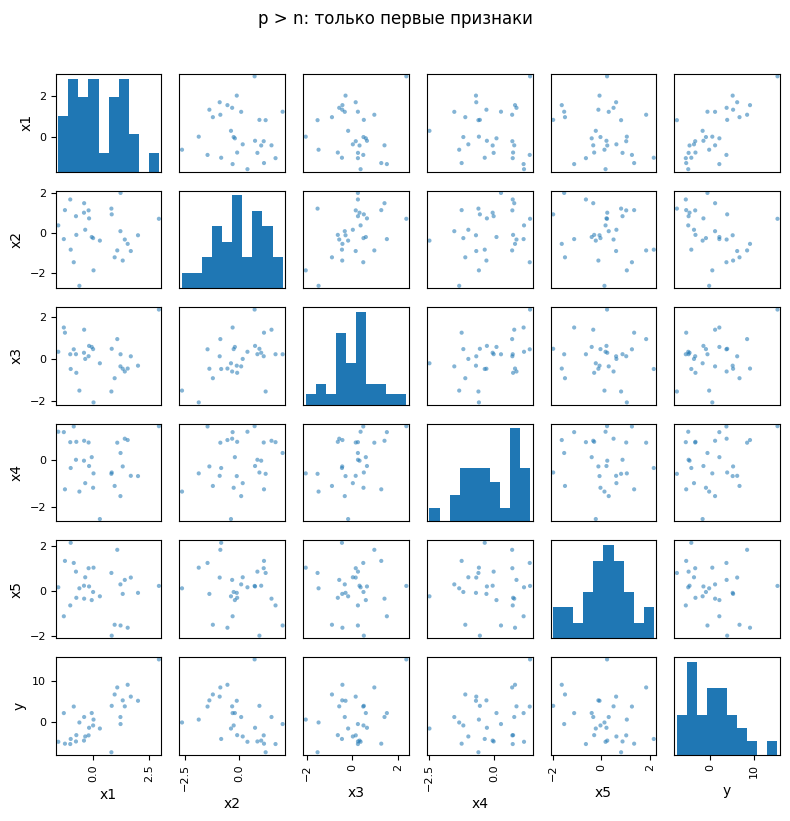

rank(X_train) = 30 при p = 100 и n_train = 30
Train: model    OLS train
MAE            0.0
RMSE           0.0
R2             1.0
dtype: object
Test : model    OLS test
MAE      2.987831
RMSE     3.432047
R2       0.374592
dtype: object
Норма коэффициентов OLS: 2.879040859582795
Лучший Ridge alpha: 0.001
model    Ridge test
MAE        2.987812
RMSE       3.432044
R2         0.374593
dtype: object


In [12]:
# Пример 10. p > n
n, p = 50, 100
X_pn = np.random.normal(size=(n, p))
beta_pn = np.zeros(p)
beta_pn[:5] = [3, -2.5, 2, 1.5, -1]
y_pn = X_pn @ beta_pn + np.random.normal(0, 1.5, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_pn, y_pn)
show_split_shapes(Xtr, Xv, Xte)

small_df = pd.DataFrame(Xtr[:, :5], columns=[f'x{i+1}' for i in range(5)])
small_df['y'] = ytr
matrix_plot(small_df, title='p > n: только первые признаки')

pn_ols = LinearRegression().fit(Xtr, ytr)
print('rank(X_train) =', matrix_rank(Xtr), 'при p =', p, 'и n_train =', len(Xtr))
print('Train:', reg_metrics(ytr, pn_ols.predict(Xtr), 'OLS train'))
print('Test :', reg_metrics(yte, pn_ols.predict(Xte), 'OLS test'))
print('Норма коэффициентов OLS:', np.linalg.norm(pn_ols.coef_))

# Покажем Ridge как один из способов стабилизации.
alphas = np.logspace(-3, 3, 25)
rows = []
models = {}
for a in alphas:
    m = Ridge(alpha=a).fit(Xtr, ytr)
    rows.append({'alpha': a, 'val_RMSE': np.sqrt(mean_squared_error(yv, m.predict(Xv)))})
    models[a] = m
ridge_tab = pd.DataFrame(rows)
best_a = float(ridge_tab.loc[ridge_tab.val_RMSE.idxmin(), 'alpha'])
ridge_pn = models[best_a]

print('Лучший Ridge alpha:', best_a)
print(reg_metrics(yte, ridge_pn.predict(Xte), 'Ridge test'))


# 11. Сильно коррелированные признаки

Сильная мультиколлинеарность означает, что несколько признаков несут почти одну и ту же информацию. Предсказания модели могут оставаться приемлемыми, но отдельные коэффициенты становятся нестабильными: небольшое изменение выборки приводит к заметному изменению $\hat\beta$.


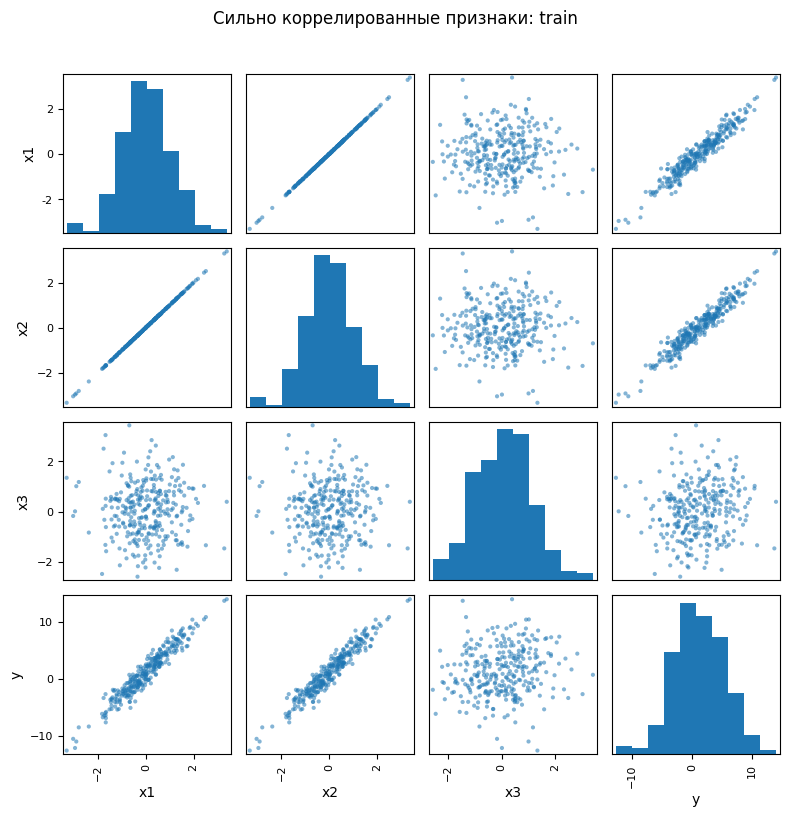

Корреляция признаков:
          x1        x2        x3
x1  1.000000  0.999980 -0.002976
x2  0.999980  1.000000 -0.002925
x3 -0.002976 -0.002925  1.000000
  feature  coef_original  coef_after_small_perturbation
0      x1     -15.424169                     -15.251360
1      x2      19.393944                      19.209173
2      x3       0.480550                       0.483138
Сумма коэффициентов x1+x2 до/после: 3.96977511943828 3.9578128384262925
Среднее изменение предсказания на test: 0.010292778050772038
model    OLS correlated
MAE            0.721046
RMSE           0.927225
R2             0.945004
dtype: object
cond(X_train) = 312.93033462818903


In [13]:
# Пример 11. Два почти одинаковых признака
n = 500
z = np.random.normal(size=n)
x1 = z + np.random.normal(0, 0.005, n)
x2 = z + np.random.normal(0, 0.005, n)
x3 = np.random.normal(size=n)
X_corr = np.column_stack([x1, x2, x3])
y_corr = 1 + 2*x1 + 2*x2 + 0.5*x3 + np.random.normal(0, 1.0, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_corr, y_corr)
df = pd.DataFrame(Xtr, columns=['x1', 'x2', 'x3'])
df['y'] = ytr
matrix_plot(df, title='Сильно коррелированные признаки: train')
print('Корреляция признаков:')
print(df[['x1','x2','x3']].corr())

m1 = LinearRegression().fit(Xtr, ytr)

# Небольшое возмущение train-ответов.
ytr_perturbed = ytr + np.random.normal(0, 0.10, len(ytr))
m2 = LinearRegression().fit(Xtr, ytr_perturbed)

coef_compare = pd.DataFrame({
    'feature': ['x1', 'x2', 'x3'],
    'coef_original': m1.coef_,
    'coef_after_small_perturbation': m2.coef_
})
print(coef_compare)
print('Сумма коэффициентов x1+x2 до/после:', m1.coef_[0]+m1.coef_[1], m2.coef_[0]+m2.coef_[1])
print('Среднее изменение предсказания на test:', np.mean(np.abs(m1.predict(Xte)-m2.predict(Xte))))
print(reg_metrics(yte, m1.predict(Xte), 'OLS correlated'))
print('cond(X_train) =', cond(Xtr))


# 12. Плохо обусловленная матрица

Число обусловленности

$$
\kappa(X) = \frac{\sigma_{max}}{\sigma_{min}}
$$

показывает, насколько решение чувствительно к малым возмущениям данных. При очень большом $\kappa(X)$ небольшая ошибка округления или шум могут сильно изменить коэффициенты.

Типичные выходы:

- использовать SVD / псевдообратную матрицу вместо явного вычисления $(X^TX)^{-1}$;
- масштабировать признаки;
- удалить почти линейно зависимые признаки;
- применить Ridge-регуляризацию;
- понизить размерность.


In [14]:
# Пример 12. Плохо обусловленная Vandermonde-матрица
n = 240
x_bad = np.random.uniform(0.95, 1.05, n)
y_bad = 2 + 3*(x_bad-1) - 4*(x_bad-1)**2 + np.random.normal(0, 0.01, n)

X_base = x_bad.reshape(-1, 1)
Xtr0, Xv0, Xte0, ytr, yv, yte = split_3way(X_base, y_bad)

poly10 = PolynomialFeatures(degree=10, include_bias=False)
Xtr = poly10.fit_transform(Xtr0)
Xv = poly10.transform(Xv0)
Xte = poly10.transform(Xte0)

print('cond(X_train)   =', cond(Xtr))
print('cond(X^T X)     =', cond(Xtr.T @ Xtr))

# Решение через lstsq/SVD
beta_lstsq, *_ = np.linalg.lstsq(
    np.column_stack([np.ones(len(Xtr)), Xtr]), ytr, rcond=None
)
pred_lstsq = np.column_stack([np.ones(len(Xte)), Xte]) @ beta_lstsq

# Явные нормальные уравнения — специально показываем как потенциально нестабильный путь.
Xd = np.column_stack([np.ones(len(Xtr)), Xtr])
try:
    beta_normal = np.linalg.solve(Xd.T @ Xd, Xd.T @ ytr)
    pred_normal = np.column_stack([np.ones(len(Xte)), Xte]) @ beta_normal
    normal_metrics = reg_metrics(yte, pred_normal, 'normal equations')
except np.linalg.LinAlgError:
    beta_normal = None
    normal_metrics = pd.Series({'model':'normal equations','MAE':np.nan,'RMSE':np.nan,'R2':np.nan})

# Ridge со стандартизацией, alpha выбирается по validation.
alphas = np.logspace(-8, 1, 30)
rows = []
models = {}
for a in alphas:
    pipe = Pipeline([('scale', StandardScaler()), ('ridge', Ridge(alpha=a))])
    pipe.fit(Xtr, ytr)
    rows.append({'alpha': a, 'val_RMSE': np.sqrt(mean_squared_error(yv, pipe.predict(Xv)))})
    models[a] = pipe
rt = pd.DataFrame(rows)
best_a = float(rt.loc[rt.val_RMSE.idxmin(), 'alpha'])
ridge_bad = models[best_a]

print(pd.DataFrame([
    reg_metrics(yte, pred_lstsq, 'SVD/lstsq'),
    normal_metrics,
    reg_metrics(yte, ridge_bad.predict(Xte), f'Ridge alpha={best_a:.2e}')
]))
print('Норма коэффициентов lstsq:', np.linalg.norm(beta_lstsq))

# Даже почти незаметное изменение y может сильно изменить сами коэффициенты.
ytr_tiny = ytr + np.random.normal(0, 1e-7, len(ytr))
beta_tiny, *_ = np.linalg.lstsq(Xd, ytr_tiny, rcond=None)
print('Норма изменения beta после шума 1e-7:', np.linalg.norm(beta_tiny-beta_lstsq))
print('Максимальное изменение test-предсказания:', np.max(np.abs((np.column_stack([np.ones(len(Xte)), Xte]) @ beta_tiny) - pred_lstsq)))


cond(X_train)   = 3.5002255840779204e+16
cond(X^T X)     = 5.243458648196426e+18
                  model       MAE      RMSE        R2
0             SVD/lstsq  0.007409  0.009013  0.988977
1      normal equations  0.007283  0.008991  0.989030
2  Ridge alpha=1.61e-02  0.007558  0.009247  0.988398
Норма коэффициентов lstsq: 100222179.16677004
Норма изменения beta после шума 1e-7: 4414.459214650192
Максимальное изменение test-предсказания: 9.313225746154785e-08


# 13. Один значимый и много незначимых признаков

Добавление нерелевантных признаков не обязано ухудшать train-ошибку, но увеличивает дисперсию оценки и может ухудшить качество на новых данных. Сравним полную модель с моделью, использующей только действительно информативный признак.


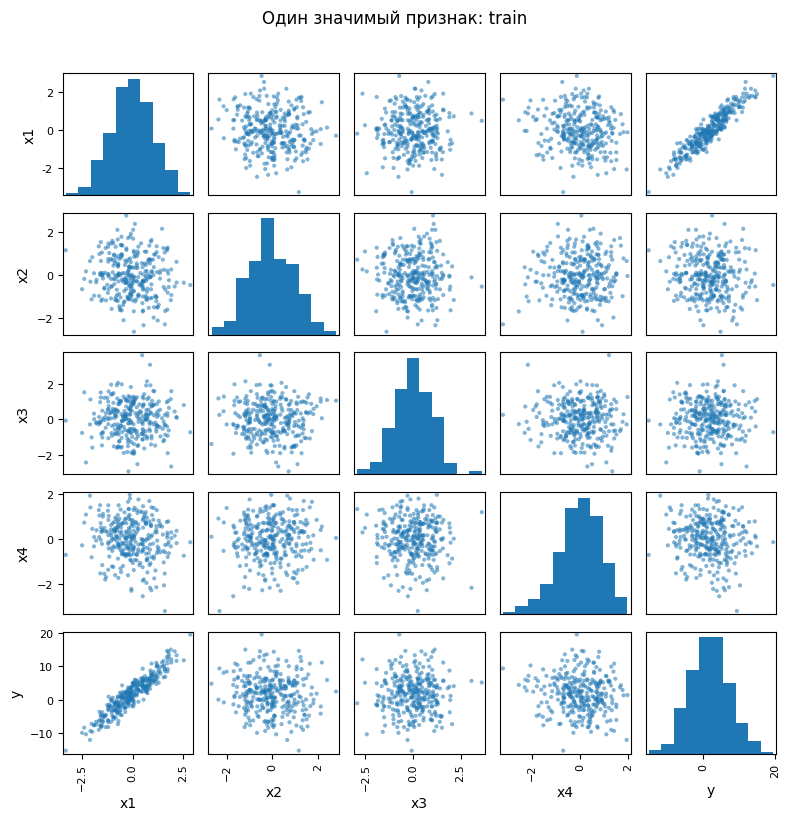

             model       MAE      RMSE        R2
0  all 20 features  1.297930  1.670171  0.913707
1          only x1  1.264029  1.609697  0.919843
   feature      coef
0       x1  5.101868
1       x2 -0.050051
2       x3  0.015424
3       x4  0.122127
4       x5  0.054616
5       x6  0.014447
6       x7  0.162410
7       x8 -0.078835
8       x9  0.074613
9      x10 -0.134855
10     x11 -0.045363
11     x12 -0.035337
12     x13 -0.077357
13     x14  0.116063
14     x15  0.232848
15     x16  0.083851
16     x17  0.072916
17     x18  0.083504
18     x19  0.026517
19     x20 -0.134409


In [15]:
# Пример 13. Один полезный признак из двадцати
n, p = 500, 20
X_one = np.random.normal(size=(n, p))
y_one = 2 + 5*X_one[:, 0] + np.random.normal(0, 2.0, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_one, y_one)
df = pd.DataFrame(Xtr[:, :4], columns=['x1','x2','x3','x4'])
df['y'] = ytr
matrix_plot(df, title='Один значимый признак: train')

full = LinearRegression().fit(Xtr, ytr)
one = LinearRegression().fit(Xtr[:, [0]], ytr)

print(pd.DataFrame([
    reg_metrics(yte, full.predict(Xte), 'all 20 features'),
    reg_metrics(yte, one.predict(Xte[:, [0]]), 'only x1')
]))

coef_df = pd.DataFrame({'feature':[f'x{i+1}' for i in range(p)], 'coef':full.coef_})
print(coef_df)


# 14. АГК как способ снижения размерности

PCA строит новые признаки как линейные комбинации исходных:

$$
z_j = v_{j1}x_1 + \cdots + v_{jp}x_p.
$$

Важно: **PCA не использует $y$** и поэтому в общем случае не знает, какие признаки значимы именно для регрессии. В следующем специально сконструированном примере два информативных признака имеют существенно большую дисперсию, поэтому первые главные компоненты почти полностью ориентируются на них. Это демонстрация возможного удачного случая, а не универсальная гарантия.


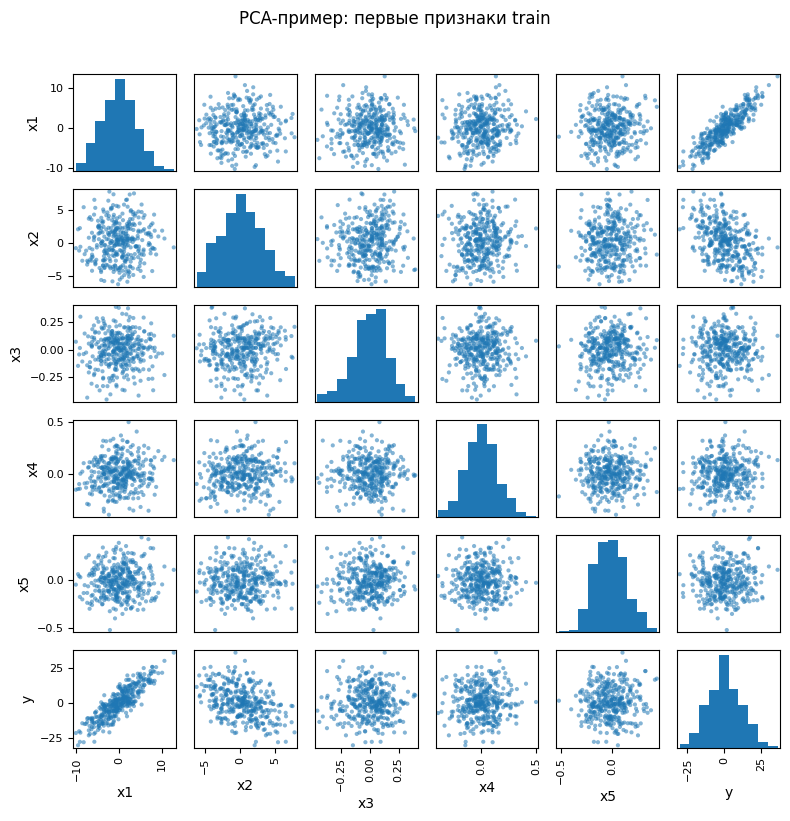

   n_components  val_RMSE
0             1  6.270383
1             2  2.249205
2             3  2.257111
3             4  2.258663
4             5  2.265606
5             6  2.264333
6             7  2.273140
Лучшее число компонент по validation: 2
model    PCA(2) + OLS
MAE           1.59998
RMSE         2.022294
R2           0.969438
dtype: object
Нагрузки первых двух компонент:
          PC1       PC2
x1   0.998436 -0.055410
x2   0.055376  0.998416
x3   0.001333  0.004812
x4   0.003663  0.003871
x5   0.002431  0.002451
x6  -0.000662 -0.000030
x7   0.003956 -0.003503
x8   0.003167  0.002254
x9   0.002168  0.000563
x10  0.002294  0.002997
x11 -0.000811 -0.003928
x12 -0.001261 -0.003116
Explained variance ratio: [0.65783426 0.33294982]


In [16]:
# Пример 14. Два информативных высокодисперсионных признака + слабый шум
n, p = 600, 12
x1 = np.random.normal(0, 4.0, n)
x2 = np.random.normal(0, 3.0, n)
noise = np.random.normal(0, 0.15, size=(n, p-2))
X_pca = np.column_stack([x1, x2, noise])
y_pca = 1 + 2.5*x1 - 1.8*x2 + np.random.normal(0, 2.0, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_pca, y_pca)
df = pd.DataFrame(Xtr[:, :5], columns=['x1','x2','x3','x4','x5'])
df['y'] = ytr
matrix_plot(df, title='PCA-пример: первые признаки train')

rows=[]
models={}
for k in range(1, 8):
    pipe = Pipeline([
        ('pca', PCA(n_components=k)),
        ('lin', LinearRegression())
    ])
    pipe.fit(Xtr, ytr)
    rows.append({'n_components':k, 'val_RMSE':np.sqrt(mean_squared_error(yv, pipe.predict(Xv)))})
    models[k]=pipe

pca_table = pd.DataFrame(rows)
min_pca_rmse = pca_table.val_RMSE.min()
# Если несколько размерностей дают практически одинаковый RMSE, предпочитаем меньшую.
best_k = int(pca_table.loc[pca_table.val_RMSE <= 1.01*min_pca_rmse, 'n_components'].min())
best_pca_model = models[best_k]

print(pca_table)
print('Лучшее число компонент по validation:', best_k)
print(reg_metrics(yte, best_pca_model.predict(Xte), f'PCA({best_k}) + OLS'))

# Нагрузки первых двух компонент
pca2 = PCA(n_components=2).fit(Xtr)
loadings = pd.DataFrame(
    pca2.components_.T,
    index=[f'x{i+1}' for i in range(p)],
    columns=['PC1','PC2']
)
print('Нагрузки первых двух компонент:')
print(loadings)
print('Explained variance ratio:', pca2.explained_variance_ratio_)


# 15. Ridge, Lasso и Elastic Net

## Геометрия ограничений

Ridge соответствует ограничению

$$
\sum_j \beta_j^2 \le t,
$$

то есть в двумерном случае — кругу.

Lasso:

$$
\sum_j |\beta_j| \le t,
$$

то есть ромбу. Углы ромба способствуют точному занулению отдельных коэффициентов.

Elastic Net сочетает обе части:

$$
\lambda\left(\rho\|\beta\|_1 + \frac{1-\rho}{2}\|\beta\|_2^2\right).
$$

Параметры $\lambda$ (`alpha`) и $\rho$ (`l1_ratio`) должны подбираться **только на validation**, после чего одна выбранная модель оценивается на test.


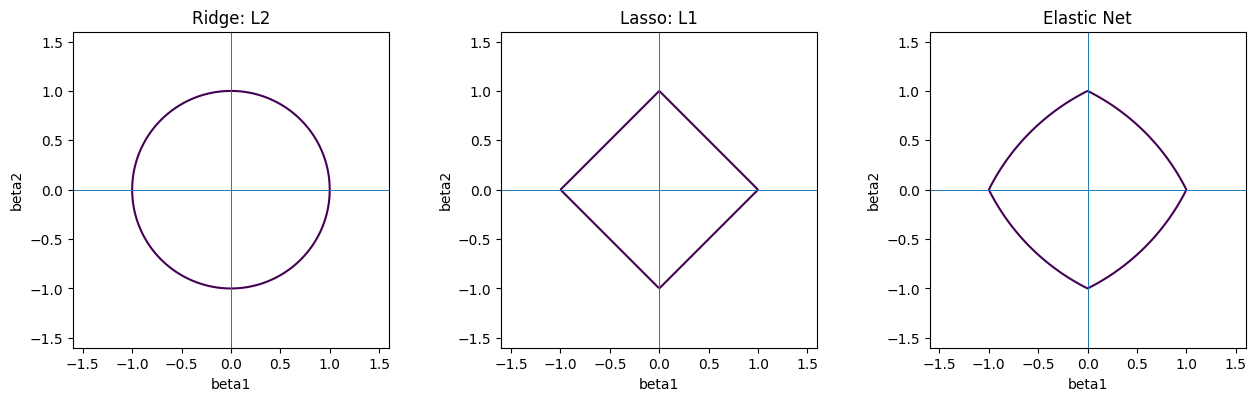

In [17]:
# Пример 15A. Геометрия ограничений в плоскости beta1-beta2
b = np.linspace(-1.6, 1.6, 500)
B1, B2 = np.meshgrid(b, b)

ridge_level = B1**2 + B2**2
lasso_level = np.abs(B1) + np.abs(B2)
rho = 0.5
elastic_level = rho*(np.abs(B1)+np.abs(B2)) + (1-rho)/2*(B1**2+B2**2)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].contour(B1, B2, ridge_level, levels=[1.0])
axes[0].set_title('Ridge: L2')
axes[1].contour(B1, B2, lasso_level, levels=[1.0])
axes[1].set_title('Lasso: L1')
axes[2].contour(B1, B2, elastic_level, levels=[0.75])
axes[2].set_title('Elastic Net')
for ax in axes:
    ax.axhline(0, linewidth=0.7)
    ax.axvline(0, linewidth=0.7)
    ax.set_xlabel('beta1')
    ax.set_ylabel('beta2')
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()


ridge best on validation: {'model': 'ridge', 'alpha': 10.0, 'l1_ratio': nan, 'val_RMSE': 2.180112781970518}
lasso best on validation: {'model': 'lasso', 'alpha': 0.14384498882876628, 'l1_ratio': nan, 'val_RMSE': 2.1256377044531725}
elastic best on validation: {'model': 'elastic', 'alpha': 0.14384498882876628, 'l1_ratio': 0.8, 'val_RMSE': 2.130585447684724}
                           model       MAE      RMSE        R2
0                ridge: alpha=10  1.808429  2.299458  0.811906
1             lasso: alpha=0.144  1.788223  2.254301  0.819221
2  elastic: alpha=0.144, rho=0.8  1.797850  2.275072  0.815875


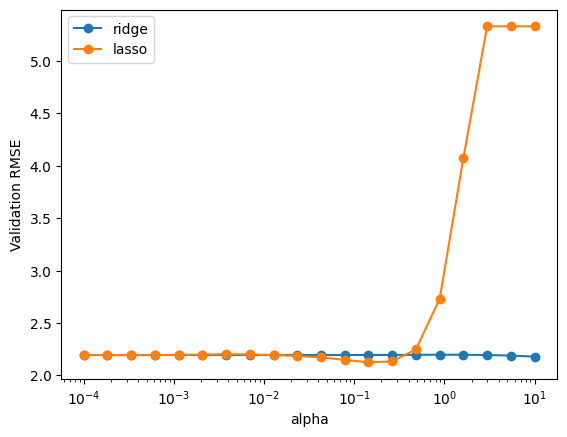

In [18]:
# Пример 15B. Подбор регуляризации на validation
n, p = 500, 20
latent = np.random.normal(size=(n, 5))
X_reg = np.column_stack([
    latent,
    latent[:, [0]] + np.random.normal(0, 0.05, (n,1)),
    latent[:, [1]] + np.random.normal(0, 0.05, (n,1)),
    np.random.normal(size=(n, p-7))
])
true_beta = np.zeros(p)
true_beta[:5] = [3, -2.5, 2, 0, 1.5]
y_reg = 1 + X_reg @ true_beta + np.random.normal(0, 2.0, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_reg, y_reg)

alphas = np.logspace(-4, 1, 20)
results=[]
best_models={}

for kind in ['ridge','lasso']:
    for a in alphas:
        est = Ridge(alpha=a) if kind=='ridge' else Lasso(alpha=a, max_iter=10000)
        pipe = Pipeline([('scale', StandardScaler()), (kind, est)])
        pipe.fit(Xtr, ytr)
        rmse = np.sqrt(mean_squared_error(yv, pipe.predict(Xv)))
        results.append({'model':kind,'alpha':a,'l1_ratio':np.nan,'val_RMSE':rmse})
        best_models[(kind,a,None)] = pipe

for a in alphas:
    for rho in [0.2, 0.5, 0.8]:
        pipe = Pipeline([
            ('scale', StandardScaler()),
            ('elastic', ElasticNet(alpha=a, l1_ratio=rho, max_iter=10000))
        ])
        pipe.fit(Xtr, ytr)
        rmse = np.sqrt(mean_squared_error(yv, pipe.predict(Xv)))
        results.append({'model':'elastic','alpha':a,'l1_ratio':rho,'val_RMSE':rmse})
        best_models[('elastic',a,rho)] = pipe

res = pd.DataFrame(results)
selected=[]
for kind in ['ridge','lasso','elastic']:
    row = res[res.model==kind].sort_values('val_RMSE').iloc[0]
    rho = None if kind!='elastic' else float(row.l1_ratio)
    m = best_models[(kind,float(row.alpha),rho)]
    selected.append(reg_metrics(yte, m.predict(Xte), f"{kind}: alpha={row.alpha:.3g}" + (f", rho={rho}" if rho is not None else '')))
    print(kind, 'best on validation:', row.to_dict())

print(pd.DataFrame(selected))

for kind in ['ridge','lasso']:
    part = res[res.model==kind]
    plt.plot(part.alpha, part.val_RMSE, marker='o', label=kind)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Validation RMSE')
plt.legend()
plt.show()


# 16. Выбор модели с помощью AIC и BIC

Для линейной регрессии с гауссовым шумом, с точностью до общей константы, можно использовать

$$
AIC = n\ln\left(\frac{RSS}{n}\right) + 2k,
$$

$$
BIC = n\ln\left(\frac{RSS}{n}\right) + k\ln n,
$$

где $k$ — число оцениваемых параметров. BIC штрафует сложность сильнее, особенно при большом $n$.

Здесь validation намеренно не используется: AIC/BIC сами являются критериями выбора модели. Test всё равно сохраняется независимым до финальной проверки.


In [19]:
# Пример 16. Полный перебор подмножеств признаков
n, p = 420, 8
X_ic = np.random.normal(size=(n, p))
beta_ic = np.array([3.0, -2.0, 1.5, 0, 0, 0, 0, 0])
y_ic = 2 + X_ic @ beta_ic + np.random.normal(0, 2.0, n)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_ic, y_ic)

records=[]
for k_features in range(1, p+1):
    for subset in combinations(range(p), k_features):
        subset = list(subset)
        m = LinearRegression().fit(Xtr[:, subset], ytr)
        pred = m.predict(Xtr[:, subset])
        rss = np.sum((ytr-pred)**2)
        ntr = len(ytr)
        k_params = len(subset) + 1  # + intercept
        aic = ntr*np.log(rss/ntr) + 2*k_params
        bic = ntr*np.log(rss/ntr) + k_params*np.log(ntr)
        records.append({'features':tuple(i+1 for i in subset), 'k':len(subset), 'AIC':aic, 'BIC':bic})

ic = pd.DataFrame(records)
best_aic = ic.sort_values('AIC').iloc[0]
best_bic = ic.sort_values('BIC').iloc[0]

print('Top AIC:')
print(ic.sort_values('AIC').head(10))
print()
print('Top BIC:')
print(ic.sort_values('BIC').head(10))

rows=[]
for criterion, row in [('AIC',best_aic),('BIC',best_bic)]:
    subset = [i-1 for i in row.features]
    m = LinearRegression().fit(Xtr[:, subset], ytr)
    rows.append(reg_metrics(yte, m.predict(Xte[:, subset]), f'{criterion}: {row.features}'))

print()
print('Истинно значимые признаки: (1, 2, 3)')
print(pd.DataFrame(rows))


Top AIC:
            features  k         AIC         BIC
36         (1, 2, 3)  3  353.290640  367.408356
92      (1, 2, 3, 4)  4  354.204781  371.851927
96      (1, 2, 3, 8)  4  354.500405  372.147550
93      (1, 2, 3, 5)  4  354.591868  372.239013
94      (1, 2, 3, 6)  4  355.190853  372.837998
95      (1, 2, 3, 7)  4  355.274026  372.921171
165  (1, 2, 3, 4, 8)  5  355.329721  376.506295
162  (1, 2, 3, 4, 5)  5  355.542669  376.719244
168  (1, 2, 3, 5, 8)  5  355.937406  377.113980
163  (1, 2, 3, 4, 6)  5  356.137787  377.314361

Top BIC:
            features  k         AIC         BIC
36         (1, 2, 3)  3  353.290640  367.408356
92      (1, 2, 3, 4)  4  354.204781  371.851927
96      (1, 2, 3, 8)  4  354.500405  372.147550
93      (1, 2, 3, 5)  4  354.591868  372.239013
94      (1, 2, 3, 6)  4  355.190853  372.837998
95      (1, 2, 3, 7)  4  355.274026  372.921171
165  (1, 2, 3, 4, 8)  5  355.329721  376.506295
162  (1, 2, 3, 4, 5)  5  355.542669  376.719244
168  (1, 2, 3, 5, 8) 

# 17. Линейная регрессия на реальных данных

Рассмотрим два набора данных, встроенных в scikit-learn и не требующих скачивания из интернета.

1. **Diabetes** — предсказание количественного показателя прогрессирования диабета по десяти числовым признакам.
2. **Linnerud** — небольшой набор наблюдений о физических упражнениях и физиологических измерениях. Для простоты будем прогнозировать `Waist` по трём упражнениям.


train: (265, 10) validation: (88, 10) test: (89, 10)


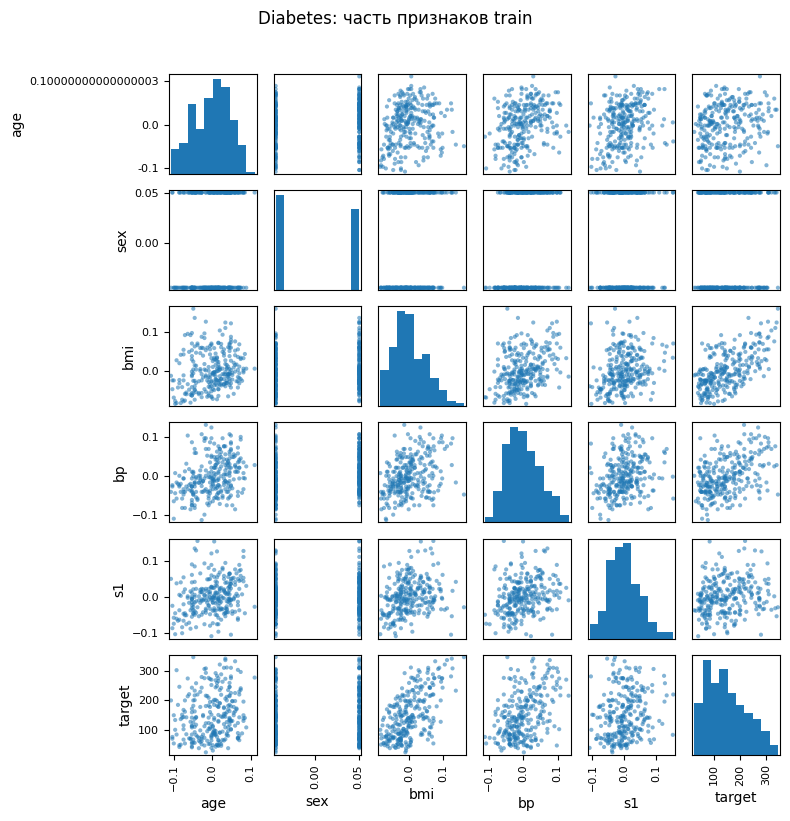

model    Diabetes OLS
MAE         46.724017
RMSE        56.970268
R2           0.438914
dtype: object
Коэффициенты модели:
s1    -655.907388
s5     594.015429
bmi    592.277235
bp     361.541232
s2     353.716364
sex   -227.043449
s4     142.873694
s6      31.673180
age     18.087998
s3      14.412655
dtype: float64


In [20]:
# Пример 17A. Diabetes
diabetes = load_diabetes(as_frame=True)
X_real = diabetes.data.values
y_real = diabetes.target.values
feature_names = list(diabetes.data.columns)

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_real, y_real)
show_split_shapes(Xtr, Xv, Xte)

df = pd.DataFrame(Xtr[:, :5], columns=feature_names[:5])
df['target'] = ytr
matrix_plot(df, title='Diabetes: часть признаков train')

real_model = LinearRegression().fit(Xtr, ytr)
print(reg_metrics(yte, real_model.predict(Xte), 'Diabetes OLS'))

coef = pd.Series(real_model.coef_, index=feature_names).sort_values(key=np.abs, ascending=False)
print('Коэффициенты модели:')
print(coef)


train: (12, 3) validation: (4, 3) test: (4, 3)


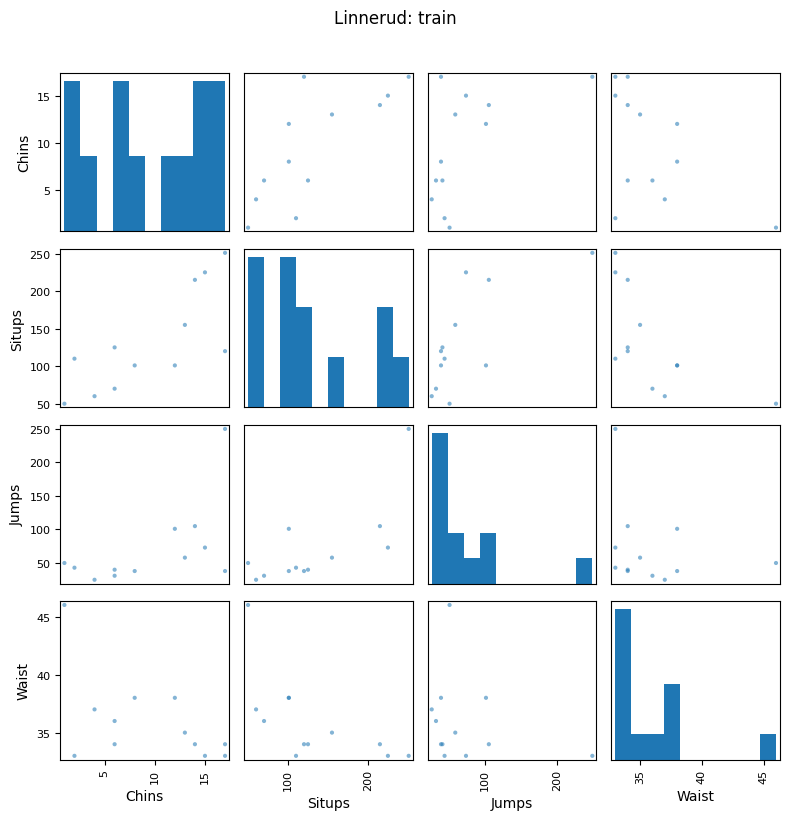

Признаки: ['Chins', 'Situps', 'Jumps']
Коэффициенты: [-0.07089177 -0.04880346  0.0262797 ]
model    Linnerud OLS
MAE          1.118596
RMSE         1.152853
R2           0.505462
dtype: object


In [21]:
# Пример 17B. Linnerud
lin = load_linnerud(as_frame=True)
X_lin = lin.data.values
# Physiological targets: Weight, Waist, Pulse
waist_col = list(lin.target.columns).index('Waist')
y_lin = lin.target.values[:, waist_col]

Xtr, Xv, Xte, ytr, yv, yte = split_3way(X_lin, y_lin)
show_split_shapes(Xtr, Xv, Xte)

df = pd.DataFrame(Xtr, columns=lin.data.columns)
df['Waist'] = ytr
matrix_plot(df, title='Linnerud: train')

lin_model = LinearRegression().fit(Xtr, ytr)
print('Признаки:', list(lin.data.columns))
print('Коэффициенты:', lin_model.coef_)
print(reg_metrics(yte, lin_model.predict(Xte), 'Linnerud OLS'))


# Итоги семинара

В этой практике линейная регрессия рассматривалась не только как формула для построения прямой, а как модель, поведение которой зависит от структуры данных и численных свойств матрицы признаков.

Основные наблюдения:

- при действительно линейной зависимости OLS хорошо восстанавливает коэффициенты;
- полный перебор коэффициентов плохо масштабируется по числу признаков;
- SVD даёт устойчивый способ решать задачу наименьших квадратов;
- нелинейность можно описывать линейной моделью после подходящего преобразования признаков;
- аутлаеры особенно опасны для квадратичной функции потерь;
- смеси разных режимов могут требовать нескольких локальных моделей;
- случаи $p>n$, мультиколлинеарность и плохая обусловленность делают коэффициенты нестабильными;
- PCA снижает размерность, но сам по себе не использует целевую переменную;
- Ridge, Lasso и Elastic Net требуют настройки гиперпараметров на validation;
- AIC и BIC позволяют сравнивать модели разной сложности без использования test;
- финальная оценка всегда должна проводиться на данных, не использовавшихся для выбора модели и её параметров.
